In [16]:
import pandas as pd 

df = pd.read_csv('Cleaned_Dataset.csv')

recommendation_df = df.copy()

print(recommendation_df['release_year'].head())
print(recommendation_df['release_year'].dtype)


0    2020
1    2021
2    2021
3    2021
4    1993
Name: release_year, dtype: int64
int64


In [17]:
recommendation_df['release_year'] = pd.to_numeric(
    recommendation_df['release_year'],
    errors='coerce'
)

release_year_df = recommendation_df.dropna(
    subset=['release_year']
).copy()

release_year_df['release_year'] = (
    release_year_df['release_year'].astype(int)
)

print('Rows after cleaning:', len(release_year_df))
print(release_year_df[['title', 'release_year']].head())

Rows after cleaning: 8790
                              title  release_year
0              Dick Johnson Is Dead          2020
1                         Ganglands          2021
2                     Midnight Mass          2021
3  Confessions of an Invisible Girl          2021
4                           Sankofa          1993


In [18]:
print('Earliest year:', release_year_df['release_year'].min())
print('Latest year:', release_year_df['release_year'].max())

Earliest year: 1925
Latest year: 2021


In [19]:
yearly_content = (
    release_year_df['release_year']
    .value_counts()
    .sort_index()
)

print(yearly_content)

release_year
1925       1
1942       2
1943       3
1944       3
1945       4
        ... 
2017    1030
2018    1146
2019    1030
2020     953
2021     592
Name: count, Length: 74, dtype: int64


In [20]:
yearly_trend = (
    release_year_df
    .groupby('release_year')
    .size()
    .reset_index(name='content_count')
)

yearly_trend.head(10)

,release_year,content_count
0,1925,1
1,1942,2
2,1943,3
3,1944,3
4,1945,4
5,1946,2
6,1947,1
7,1954,2
8,1955,3
9,1956,2


In [21]:
top_years = yearly_trend.sort_values(
    'content_count',
    ascending=False
).head(10)
top_years

,release_year,content_count
70,2018,1146
69,2017,1030
71,2019,1030
72,2020,953
68,2016,901
73,2021,592
67,2015,555
66,2014,352
65,2013,286
64,2012,236


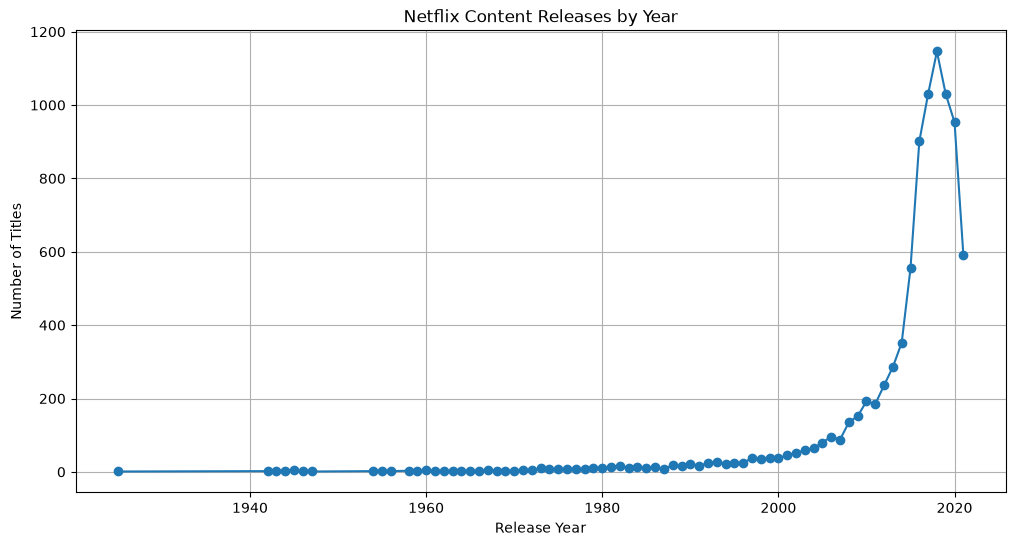

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    yearly_trend['release_year'],
    yearly_trend['content_count'],
    marker='o'
)

plt.title('Netflix Content Releases by Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.grid('True')
plt.show()

In [23]:
peak_year = yearly_trend.loc[
    yearly_trend['content_count'].idxmax()
]
print(peak_year['release_year'])
print(peak_year['content_count'])

2018
1146


In [24]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

X = yearly_trend[['release_year']]
y = yearly_trend['content_count']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print('Training Data:', len(X_train))
print('Testing Data:', len(X_test))



Training Data: 59
Testing Data: 15


In [12]:
model=LinearRegression()
model.fit(X_train, y_train)

print('Model Trained successfully')


Model Trained successfully


In [13]:
y_pred = model.predict(X_test)

print('Predictions:')
print(y_pred)

Predictions:
[-201.47856437  334.92941963  -30.80329674 -364.02643831   50.47064023
  416.2033566   -95.82244631   99.23500242  -79.56765892  269.91027005
  351.18420702   74.85282133 -112.0772337   188.63633308 -193.35117067]


In [14]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print('Mean Absolute Error:', mae)
print('Root Mean Squared Error:', rmse)

Mean Absolute Error: 136.2761430792103
Root Mean Squared Error: 160.18350994867902


We are predicting the content that will be made in the latter years.
For Example:

| release_year  | predicted_content |
| ------------- | ----------------: |
| Future year 1 |               ... |
| Future year 2 |               ... |
| Future year 3 |               ... |
| Future year 4 |               ... |
| Future year 5 |               ... |


In [15]:
latest_year = release_year_df['release_year'].max()

future_years = pd.DataFrame({
    'release_year': range(latest_year + 1, latest_year + 6)
})

future_predictions = model.predict(future_years)

future_forecast = future_years.copy()
future_forecast['predicted_content'] = future_predictions

future_forecast

,release_year,predicted_content
0,2022,424.330750
1,2023,432.458144
2,2024,440.585538
3,2025,448.712931
4,2026,456.840325


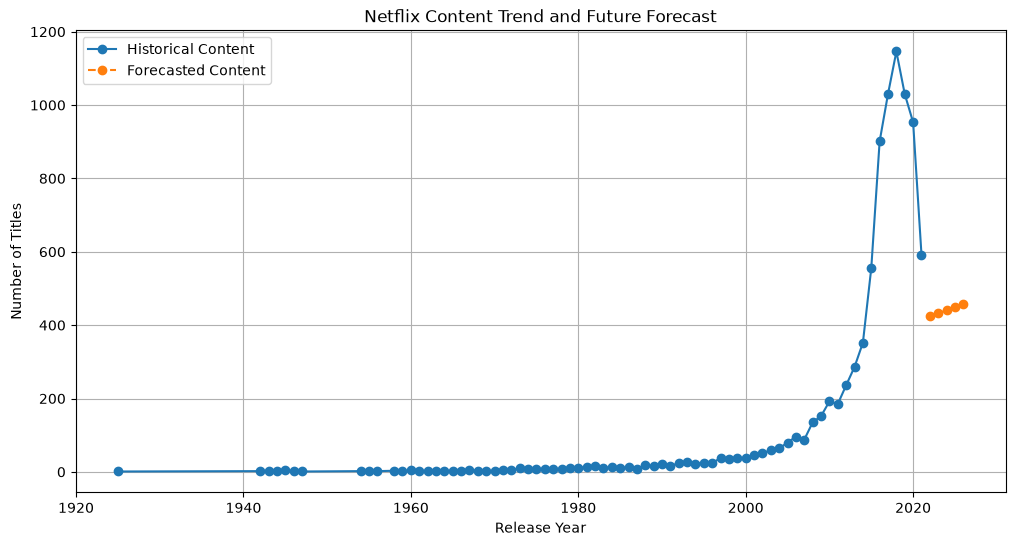

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    yearly_trend['release_year'],
    yearly_trend['content_count'],
    marker='o',
    label='Historical Content'
)

plt.plot(
    future_forecast['release_year'],
    future_forecast['predicted_content'],
    marker='o',
    linestyle='--',
    label='Forecasted Content'
)

plt.title('Netflix Content Trend and Future Forecast')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.legend()
plt.grid('true')
plt.show()

In [27]:
print('Future Netflix Content Forecast')

for _, row in future_forecast.iterrows():
    print(
        f'{int(row['release_year'])}: '
        f'{row['predicted_content']:.0f} predicted titles'
    )

Future Netflix Content Forecast
2022: 424 predicted titles
2023: 432 predicted titles
2024: 441 predicted titles
2025: 449 predicted titles
2026: 457 predicted titles


In [28]:
first_prediction = future_forecast['predicted_content'].iloc[0]
last_prediction = future_forecast['predicted_content'].iloc[-1]

change = last_prediction - first_prediction

print("Change over forecast period:", round(change, 2))

if change > 0:
    print("Forecast indicates an increasing trend.")
elif change < 0:
    print("Forecast indicates a decreasing trend.")
else:
    print("Forecast indicates a stable trend.")

Change over forecast period: 32.51
Forecast indicates an increasing trend.


In [29]:
print('Task 4 - Forecasting Result')
print('=' * 40)

print(f'Model MAE: {mae:.2f}')
print(f'Model RMSE: {rmse:.2f}')

print(f'\nHistorical period: {release_year_df['release_year'].min()} '
      f'to {release_year_df['release_year'].max()}')

print('\nFuture Forecast: ')

for _, row in future_forecast.iterrows():
    print(
        f'{int(row['release_year'])}: '
        f'{row['predicted_content']:.0f} predicted titles'
    )

print('\nInterpretation:')

if change < 0:
    print('The model forecasts an overall increase in Netflix content over the period.')

elif change < 0:
    print(
        'The model forecasts an overall decrease in Netflix content over the  forecast period. '
    )

else:
    print(
        'The model forecasts a relatively stable level of Netflix content over the forecast period. '
    )


print(
    'The MAE and RMSE provide measures of the models prediction error.'
    'Lower values indicate better predictive accuracy.'
)

Task 4 - Forecasting Result
Model MAE: 136.28
Model RMSE: 160.18

Historical period: 1925 to 2021

Future Forecast: 
2022: 424 predicted titles
2023: 432 predicted titles
2024: 441 predicted titles
2025: 449 predicted titles
2026: 457 predicted titles

Interpretation:
The model forecasts a relatively stable level of Netflix content over the forecast period. 
The MAE and RMSE provide measures of the models prediction error.Lower values indicate better predictive accuracy.
